In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from sklearn.cluster import KMeans

uploaded = files.upload()
data = pd.read_csv(next(iter(uploaded.keys())))

print("Dataset loaded successfully")
display(data.head())


Saving Rajasthan_Heatwave_2006_2025.csv to Rajasthan_Heatwave_2006_2025 (1).csv
Dataset loaded successfully


,YEAR,MONTH,DAY,WIND_U10,WIND_V10,MSLP,BLH,GEOP,TEMP2M,TMAX,...,RAIN,SRAD,EVAP,SOILT1,SOILM1,LAI,HEATWAVE,LAT,LON,DISTRICT
0,2006,3,1,-0.223022,-0.440903,101036.375,2020.7317,1671.1079,304.75806,303.54395,...,0.0,3117056,-0.000023,312.75903,0.024887,0.515625,0,25.75,71.5,Barmer
1,2006,3,2,-1.344009,-0.294922,101076.440,2265.7910,1671.1079,306.45337,304.95703,...,0.0,3131200,-0.000024,312.66943,0.024345,0.515625,0,25.75,71.5,Barmer
2,2006,3,3,-0.960449,1.522965,101033.750,3152.6023,1671.1079,307.34863,306.21167,...,0.0,3105536,-0.000024,313.12280,0.023773,0.515625,0,25.75,71.5,Barmer
3,2006,3,4,2.704514,1.733017,100896.940,3146.9475,1671.1079,307.43457,306.70508,...,0.0,3126528,-0.000024,314.12085,0.023147,0.515625,0,25.75,71.5,Barmer
4,2006,3,5,2.717834,2.464432,101014.190,2069.5261,1671.1079,306.19507,304.88306,...,0.0,2776448,-0.000041,312.00806,0.027964,0.515625,0,25.75,71.5,Barmer


In [5]:

print("Dataset Shape:", data.shape)
print("\nDataset Information:")
data.info()

print("\nStatistical Summary:")
display(data.describe())


Dataset Shape: (21960, 23)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21960 entries, 0 to 21959
Data columns (total 23 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   YEAR      21960 non-null  int64  
 1   MONTH     21960 non-null  int64  
 2   DAY       21960 non-null  int64  
 3   WIND_U10  21960 non-null  float64
 4   WIND_V10  21960 non-null  float64
 5   MSLP      21960 non-null  float64
 6   BLH       21960 non-null  float64
 7   GEOP      21960 non-null  float64
 8   TEMP2M    21960 non-null  float64
 9   TMAX      21960 non-null  float64
 10  TMIN      21960 non-null  float64
 11  DEW2M     21960 non-null  float64
 12  CLOUD     21960 non-null  float64
 13  RAIN      21960 non-null  float64
 14  SRAD      21960 non-null  int64  
 15  EVAP      21960 non-null  float64
 16  SOILT1    21960 non-null  float64
 17  SOILM1    21960 non-null  float64
 18  LAI       21960 non-null  float64
 19  HEATWAVE  21960 no

,YEAR,MONTH,DAY,WIND_U10,WIND_V10,MSLP,BLH,GEOP,TEMP2M,TMAX,...,CLOUD,RAIN,SRAD,EVAP,SOILT1,SOILM1,LAI,HEATWAVE,LAT,LON
count,21960.000000,21960.000000,21960.000000,21960.000000,21960.000000,21960.000000,21960.000000,21960.000000,21960.000000,21960.000000,...,21960.000000,21960.000000,2.196000e+04,21960.000000,21960.000000,21960.000000,21960.000000,21960.00000,21960.000000,21960.000000
mean,2015.500000,4.491803,15.754098,2.475624,0.723588,100444.274043,2720.154134,2533.205122,310.489501,310.012704,...,0.229915,0.000025,3.018293e+06,-0.000121,314.923305,0.088897,0.705440,0.05000,27.194444,73.666667
std,5.766413,1.118029,8.807157,2.378115,2.603999,528.394425,956.843798,730.211149,4.823235,4.749862,...,0.292535,0.000240,3.899573e+05,0.000119,6.217636,0.074033,0.255386,0.21795,1.352897,1.598647
min,2006.000000,3.000000,1.000000,-9.852875,-10.506165,99062.310000,218.709060,1671.107900,288.333000,289.821780,...,0.000000,0.000000,1.964800e+05,-0.000597,290.145020,-0.003362,0.500000,0.00000,25.250000,71.000000
25%,2010.750000,3.000000,8.000000,0.951839,-1.194061,100032.013750,1967.295925,2038.498500,307.645260,307.107242,...,0.000000,0.000000,2.905536e+06,-0.000176,311.116080,0.025887,0.515625,0.00000,26.250000,73.000000
50%,2015.500000,4.500000,16.000000,2.605873,0.396530,100434.190000,2651.828500,2180.979000,311.434685,311.036625,...,0.110153,0.000000,3.129056e+06,-0.000075,315.802735,0.068370,0.596314,0.00000,27.000000,73.750000
75%,2020.250000,5.000000,23.000000,4.078281,2.403336,100830.265000,3439.665600,2989.502400,313.963740,313.455083,...,0.329498,0.000000,3.265216e+06,-0.000032,319.461490,0.144219,0.857788,0.00000,28.000000,75.000000
max,2025.000000,6.000000,31.000000,11.707886,10.517532,102289.690000,5547.617700,4063.225000,321.840100,320.959960,...,1.000000,0.013919,3.579648e+06,-0.000004,330.317380,0.473269,1.592163,1.00000,30.000000,75.750000


In [6]:

numeric_cols = data.select_dtypes(include=np.number).columns.tolist()

print("Numeric Columns:", numeric_cols)


Numeric Columns: ['YEAR', 'MONTH', 'DAY', 'WIND_U10', 'WIND_V10', 'MSLP', 'BLH', 'GEOP', 'TEMP2M', 'TMAX', 'TMIN', 'DEW2M', 'CLOUD', 'RAIN', 'SRAD', 'EVAP', 'SOILT1', 'SOILM1', 'LAI', 'HEATWAVE', 'LAT', 'LON']


In [7]:

min_max_data = data.copy()

for col in numeric_cols:
    min_val = data[col].min()
    max_val = data[col].max()

    if max_val != min_val:
        min_max_data[col] = (data[col] - min_val) / (max_val - min_val)
    else:
        min_max_data[col] = 0

print("Min-Max Normalization:")
display(min_max_data.head())


Min-Max Normalization:


,YEAR,MONTH,DAY,WIND_U10,WIND_V10,MSLP,BLH,GEOP,TEMP2M,TMAX,...,RAIN,SRAD,EVAP,SOILT1,SOILM1,LAI,HEATWAVE,LAT,LON,DISTRICT
0,0.0,0.0,0.000000,0.446638,0.478758,0.611662,0.338160,0.0,0.490196,0.440686,...,0.0,0.863267,0.966606,0.562925,0.059269,0.014306,0.0,0.105263,0.105263,Barmer
1,0.0,0.0,0.033333,0.394646,0.485702,0.624076,0.384147,0.0,0.540792,0.486067,...,0.0,0.867447,0.966270,0.560694,0.058132,0.014306,0.0,0.105263,0.105263,Barmer
2,0.0,0.0,0.066667,0.412436,0.572170,0.610848,0.550562,0.0,0.567510,0.526360,...,0.0,0.859862,0.965933,0.571980,0.056931,0.014306,0.0,0.105263,0.105263,Barmer
3,0.0,0.0,0.100000,0.582419,0.582161,0.568458,0.549501,0.0,0.570075,0.542206,...,0.0,0.866066,0.965428,0.596824,0.055618,0.014306,0.0,0.105263,0.105263,Barmer
4,0.0,0.0,0.133333,0.583036,0.616951,0.604788,0.347316,0.0,0.533083,0.483692,...,0.0,0.762589,0.937305,0.544231,0.065723,0.014306,0.0,0.105263,0.105263,Barmer


In [8]:

zscore_data = data.copy()

for col in numeric_cols:
    mean_val = data[col].mean()
    std_val = data[col].std()

    if std_val != 0:
        zscore_data[col] = (data[col] - mean_val) / std_val
    else:
        zscore_data[col] = 0

print("Z-Score Normalization:")
display(zscore_data.head())


Z-Score Normalization:


,YEAR,MONTH,DAY,WIND_U10,WIND_V10,MSLP,BLH,GEOP,TEMP2M,TMAX,...,RAIN,SRAD,EVAP,SOILT1,SOILM1,LAI,HEATWAVE,LAT,LON,DISTRICT
0,-1.647471,-1.334315,-1.675240,-1.134784,-0.447193,1.120566,-0.730968,-1.180614,-1.188298,-1.361882,...,-0.105205,0.253266,0.826706,-0.348086,-0.864618,-0.743249,-0.229411,-1.067668,-1.355313,Barmer
1,-1.647471,-1.334315,-1.561696,-1.606160,-0.391133,1.196390,-0.474856,-1.180614,-0.836810,-1.064383,...,-0.105205,0.289537,0.825018,-0.362497,-0.871938,-0.743249,-0.229411,-1.067668,-1.355313,Barmer
2,-1.647471,-1.334315,-1.448152,-1.444873,0.306980,1.115598,0.451953,-1.180614,-0.651196,-0.800241,...,-0.105205,0.223725,0.823331,-0.289580,-0.879669,-0.743249,-0.229411,-1.067668,-1.355313,Barmer
3,-1.647471,-1.334315,-1.334608,0.096248,0.387646,0.856682,0.446043,-1.180614,-0.633378,-0.696362,...,-0.105205,0.277556,0.820799,-0.129061,-0.888123,-0.743249,-0.229411,-1.067668,-1.355313,Barmer
4,-1.647471,-1.334315,-1.221064,0.101850,0.668527,1.078581,-0.679973,-1.180614,-0.890363,-1.079956,...,-0.105205,-0.620183,0.679893,-0.468867,-0.823065,-0.743249,-0.229411,-1.067668,-1.355313,Barmer


In [9]:

decimal_data = data.copy()

for col in numeric_cols:
    max_abs_val = data[col].abs().max()

    j = int(np.floor(np.log10(max_abs_val))) + 1 if max_abs_val > 0 else 1

    decimal_data[col] = data[col] / (10 ** j)

print("Decimal Scaling Normalization:")
display(decimal_data.head())


Decimal Scaling Normalization:


,YEAR,MONTH,DAY,WIND_U10,WIND_V10,MSLP,BLH,GEOP,TEMP2M,TMAX,...,RAIN,SRAD,EVAP,SOILT1,SOILM1,LAI,HEATWAVE,LAT,LON,DISTRICT
0,0.2006,0.3,0.01,-0.002230,-0.004409,0.101036,0.202073,0.167111,0.304758,0.303544,...,0.0,0.311706,-0.0234,0.312759,0.024887,0.051562,0.0,0.2575,0.715,Barmer
1,0.2006,0.3,0.02,-0.013440,-0.002949,0.101076,0.226579,0.167111,0.306453,0.304957,...,0.0,0.313120,-0.0236,0.312669,0.024345,0.051562,0.0,0.2575,0.715,Barmer
2,0.2006,0.3,0.03,-0.009604,0.015230,0.101034,0.315260,0.167111,0.307349,0.306212,...,0.0,0.310554,-0.0238,0.313123,0.023773,0.051562,0.0,0.2575,0.715,Barmer
3,0.2006,0.3,0.04,0.027045,0.017330,0.100897,0.314695,0.167111,0.307435,0.306705,...,0.0,0.312653,-0.0241,0.314121,0.023147,0.051562,0.0,0.2575,0.715,Barmer
4,0.2006,0.3,0.05,0.027178,0.024644,0.101014,0.206953,0.167111,0.306195,0.304883,...,0.0,0.277645,-0.0408,0.312008,0.027964,0.051562,0.0,0.2575,0.715,Barmer


In [10]:

for col in numeric_cols:
    print(f"\nColumn: {col}")

    display(pd.DataFrame({
        "Original": data[col].head(),
        "Min-Max": min_max_data[col].head(),
        "Z-Score": zscore_data[col].head(),
        "Decimal Scaling": decimal_data[col].head()
    }))



Column: YEAR


,Original,Min-Max,Z-Score,Decimal Scaling
0,2006,0.0,-1.647471,0.2006
1,2006,0.0,-1.647471,0.2006
2,2006,0.0,-1.647471,0.2006
3,2006,0.0,-1.647471,0.2006
4,2006,0.0,-1.647471,0.2006



Column: MONTH


,Original,Min-Max,Z-Score,Decimal Scaling
0,3,0.0,-1.334315,0.3
1,3,0.0,-1.334315,0.3
2,3,0.0,-1.334315,0.3
3,3,0.0,-1.334315,0.3
4,3,0.0,-1.334315,0.3



Column: DAY


...

,Original,Min-Max,Z-Score,Decimal Scaling
0,0,0.0,-0.229411,0.0
1,0,0.0,-0.229411,0.0
2,0,0.0,-0.229411,0.0
3,0,0.0,-0.229411,0.0
4,0,0.0,-0.229411,0.0



Column: LAT


,Original,Min-Max,Z-Score,Decimal Scaling
0,25.75,0.105263,-1.067668,0.2575
1,25.75,0.105263,-1.067668,0.2575
2,25.75,0.105263,-1.067668,0.2575
3,25.75,0.105263,-1.067668,0.2575
4,25.75,0.105263,-1.067668,0.2575



Column: LON


,Original,Min-Max,Z-Score,Decimal Scaling
0,71.5,0.105263,-1.355313,0.715
1,71.5,0.105263,-1.355313,0.715
2,71.5,0.105263,-1.355313,0.715
3,71.5,0.105263,-1.355313,0.715
4,71.5,0.105263,-1.355313,0.715


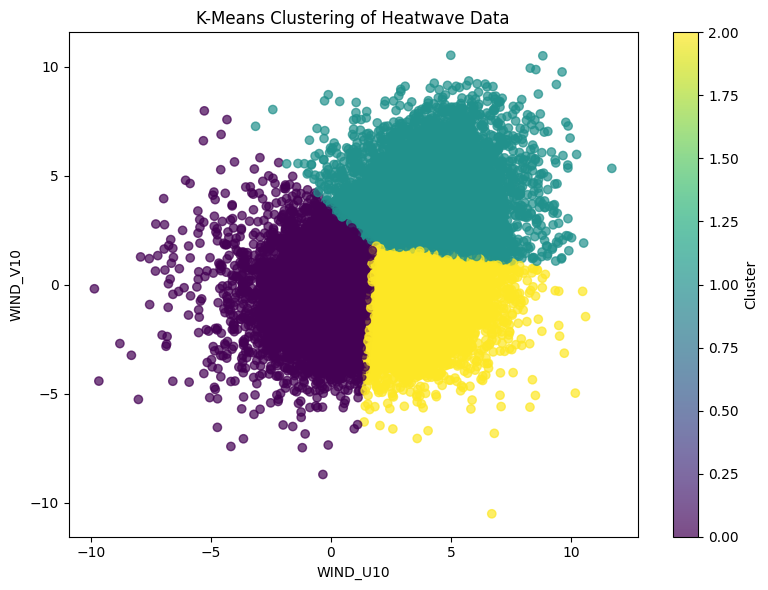

In [24]:

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import numpy as np
import pandas as pd

data.columns = data.columns.str.strip()

numeric_cols = data.select_dtypes(include=np.number).columns.tolist()

temperature_cols = [
    col for col in numeric_cols
    if "TEMP" in col.upper()
    or "T2M" in col.upper()
    or "TEMPERATURE" in col.upper()
]

if len(temperature_cols) >= 2:
    selected_columns = temperature_cols[:2]
else:
    selected_columns = [
        col for col in numeric_cols
        if col.upper() not in ["YEAR", "MONTH", "DAY"]
    ][:2]

if len(selected_columns) < 2:
    print("At least two numeric attributes are required.")
else:
    plot_data = data[selected_columns].replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    if len(plot_data) >= 3:
        kmeans = KMeans(
            n_clusters=3,
            random_state=42,
            n_init=10
        )

        cluster_labels = kmeans.fit_predict(plot_data)

        plt.figure(figsize=(8, 6))
        plt.scatter(
            plot_data[selected_columns[0]],
            plot_data[selected_columns[1]],
            c=cluster_labels,
            cmap="viridis",
            alpha=0.7
        )

        plt.xlabel(selected_columns[0])
        plt.ylabel(selected_columns[1])
        plt.title("K-Means Clustering of Heatwave Data")
        plt.colorbar(label="Cluster")
        plt.tight_layout()
        plt.show()
    else:
        print("Not enough valid records for three clusters.")


In [11]:

discretized_data = data.copy()

for col in numeric_cols:
    if data[col].nunique() >= 3:
        kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
        clusters = kmeans.fit_predict(data[[col]])

        centers = kmeans.cluster_centers_.flatten()
        order = np.argsort(centers)

        mapping = {
            old_label: new_label
            for new_label, old_label in enumerate(order)
        }

        ordered_clusters = pd.Series(clusters, index=data.index).map(mapping)

        discretized_data[col + "_Category"] = ordered_clusters.map({
            0: "Low",
            1: "Medium",
            2: "High"
        })
    else:
        discretized_data[col + "_Category"] = "Insufficient unique values"

print("K-Means Discretization Output:")
display(discretized_data.head())


K-Means Discretization Output:


,YEAR,MONTH,DAY,WIND_U10,WIND_V10,MSLP,BLH,GEOP,TEMP2M,TMAX,...,CLOUD_Category,RAIN_Category,SRAD_Category,EVAP_Category,SOILT1_Category,SOILM1_Category,LAI_Category,HEATWAVE_Category,LAT_Category,LON_Category
0,2006,3,1,-0.223022,-0.440903,101036.375,2020.7317,1671.1079,304.75806,303.54395,...,Low,Low,High,High,Medium,Low,Low,Insufficient unique values,Low,Low
1,2006,3,2,-1.344009,-0.294922,101076.440,2265.7910,1671.1079,306.45337,304.95703,...,Low,Low,High,High,Medium,Low,Low,Insufficient unique values,Low,Low
2,2006,3,3,-0.960449,1.522965,101033.750,3152.6023,1671.1079,307.34863,306.21167,...,Low,Low,High,High,Medium,Low,Low,Insufficient unique values,Low,Low
3,2006,3,4,2.704514,1.733017,100896.940,3146.9475,1671.1079,307.43457,306.70508,...,Low,Low,High,High,Medium,Low,Low,Insufficient unique values,Low,Low
4,2006,3,5,2.717834,2.464432,101014.190,2069.5261,1671.1079,306.19507,304.88306,...,High,Low,Medium,High,Medium,Low,Low,Insufficient unique values,Low,Low


In [13]:

print("Complete Discretized Dataset:")
display(discretized_data)


Complete Discretized Dataset:


,YEAR,MONTH,DAY,WIND_U10,WIND_V10,MSLP,BLH,GEOP,TEMP2M,TMAX,...,CLOUD_Category,RAIN_Category,SRAD_Category,EVAP_Category,SOILT1_Category,SOILM1_Category,LAI_Category,HEATWAVE_Category,LAT_Category,LON_Category
0,2006,3,1,-0.223022,-0.440903,101036.375,2020.73170,1671.1079,304.75806,303.54395,...,Low,Low,High,High,Medium,Low,Low,Insufficient unique values,Low,Low
1,2006,3,2,-1.344009,-0.294922,101076.440,2265.79100,1671.1079,306.45337,304.95703,...,Low,Low,High,High,Medium,Low,Low,Insufficient unique values,Low,Low
2,2006,3,3,-0.960449,1.522965,101033.750,3152.60230,1671.1079,307.34863,306.21167,...,Low,Low,High,High,Medium,Low,Low,Insufficient unique values,Low,Low
3,2006,3,4,2.704514,1.733017,100896.940,3146.94750,1671.1079,307.43457,306.70508,...,Low,Low,High,High,Medium,Low,Low,Insufficient unique values,Low,Low
4,2006,3,5,2.717834,2.464432,101014.190,2069.52610,1671.1079,306.19507,304.88306,...,High,Low,Medium,High,Medium,Low,Low,Insufficient unique values,Low,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21955,2025,6,26,-2.219376,-1.481064,100094.060,469.85406,1770.1978,305.70264,303.78710,...,High,Low,Low,Medium,Medium,Medium,Medium,Insufficient unique values,High,Medium
21956,2025,6,27,-1.746262,1.180100,99806.125,1707.57030,1770.1978,309.63060,308.89624,...,Medium,Low,Low,Low,Low,Medium,Medium,Insufficient unique values,High,Medium
21957,2025,6,28,-1.339935,1.605103,99605.250,1765.45080,1770.1978,311.13110,309.73510,...,High,Low,Medium,Low,Medium,Medium,Medium,Insufficient unique values,High,Medium
21958,2025,6,29,2.582748,1.290008,99331.310,1938.24780,1770.1978,311.31982,310.92578,...,High,Low,Medium,Low,Medium,High,Medium,Insufficient unique values,High,Medium
